In [1]:
from pathlib import Path 
import os
import dotenv
dotenv.load_dotenv()
os.chdir(Path(os.getenv("PYTHONPATH")).expanduser())

In [2]:
"""
================
Lorenz Attractor
================
"""
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from typing import Tuple, Dict, Any

np.random.seed(1)

In [3]:
DT_MIN = 0.001
T_MAX = 100_000
def lorenz(x, y, z, s=10, r=28, b=8/3):
    x_dot = s*(y - x)
    y_dot = r*x - y - x*z
    z_dot = x*y - b*z
    return x_dot, y_dot, z_dot

# ===== 1) Compute once at finest resolution and longest horizon ===== #
def simulate_full(dt_min: float, t_max: float, rng_seed: int | None = 0) -> Dict[str, np.ndarray]:
    """
    Simulate the Lorenz system once using Euler with smallest dt and largest t.
    Returns dict with arrays: 't', 'x', 'y', 'z'.
    """
    steps = int(np.floor(t_max / dt_min))
    n = steps + 1

    xs = np.empty(n, dtype=float)
    ys = np.empty(n, dtype=float)
    zs = np.empty(n, dtype=float)
    ts = np.empty(n, dtype=float)

    xs[0], ys[0], zs[0] = np.random.uniform(-20, 20, size=3)
    ts[0] = 0.0

    # Euler integration (single pass)
    for i in range(steps):
        x_dot, y_dot, z_dot = lorenz(xs[i], ys[i], zs[i])
        xs[i+1] = xs[i] + x_dot * dt_min
        ys[i+1] = ys[i] + y_dot * dt_min
        zs[i+1] = zs[i] + z_dot * dt_min
        ts[i+1] = ts[i] + dt_min

    return {"t": ts, "x": xs, "y": ys, "z": zs, "dt_min": dt_min, "t_max": t_max}

# ===== 2) Indexing helper to slice out any (dt, t) subset ===== #
def subset_trajectory(base: Dict[str, np.ndarray], dt: float, t: float) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Extract a (dt, t) trajectory from the base fine-grid trajectory.
    Requires dt to be an integer multiple of base['dt_min'] and t <= base['t_max'].
    Returns (t_sub, x_sub, y_sub, z_sub) with length = int(t/dt) + 1.
    """
    
    if t > T_MAX + 1e-12:
        raise ValueError(f"Requested t={t} exceeds base t_max={T_MAX}.")

    ratio = dt / DT_MIN
    stride = int(round(ratio))
    if not np.isclose(ratio, stride):
        raise ValueError(f"dt={dt} is not an integer multiple of dt_min={DT_MIN} (ratio={ratio}).")

    # Number of coarse steps we want:
    coarse_steps = int(np.floor(t / dt))
    # Corresponding last index on fine grid:
    last_fine_idx = coarse_steps * stride

    # Slice with stride; +1 to include the starting point (i=0)
    x_sub = base["x"][:last_fine_idx + 1:stride]
    y_sub = base["y"][:last_fine_idx + 1:stride]
    z_sub = base["z"][:last_fine_idx + 1:stride]
    t_sub = base["t"][:last_fine_idx + 1:stride]

    # Guard: ensure exact expected length (coarse_steps+1)
    expected_len = coarse_steps + 1
    if len(t_sub) != expected_len:
        # Trim or pad (trim is typical if any off-by-ones appear due to float rounding)
        t_sub = t_sub[:expected_len]
        x_sub = x_sub[:expected_len]
        y_sub = y_sub[:expected_len]
        z_sub = z_sub[:expected_len]

    return t_sub, x_sub, y_sub, z_sub

# ===== 3) Analysis/plot wrapper replicating your stats & hist ===== #
def report_and_plot(dt: float, t: float, t_arr: np.ndarray, x: np.ndarray, y: np.ndarray, z: np.ndarray) -> None:
    data = pd.DataFrame({"x": x, "y": y, "z": z}, index=t_arr)
    print(f"dt={dt}, t={t}")
    print(pd.DataFrame([data.mean(), data.var()]))
    labels = {0: 'x', 1: 'y', 2: 'z'}
    fig, axs = plt.subplots(1, 3, layout='constrained', figsize=(13, 4))
    for i, arr in enumerate([x, y, z]):
        sns.histplot(arr, bins=200, ax=axs[i])
        axs[i].set_xlabel(f'{labels[i]}')
        axs[i].set_ylabel('')
        axs[i].grid(True)
    fig.suptitle(f'dt={dt}, t={t:,}')
    plt.show()
    fig.savefig("small_dt_small_t.pdf", bbox_inches="tight")
    fig.savefig("small_dt_small_t.png", dpi=300, bbox_inches="tight")

In [4]:
#base = simulate_full(dt_min=DT_MIN, t_max=T_MAX + 100, rng_seed=0)
df = pd.read_pickle('data/lorenz_data.pkl')
base = df.copy()
df.head()

,t,x,y,z,dt_min,t_max
0,0.000,-7.906697,-14.129764,-16.306456,0.001,100100
1,0.001,-7.968928,-14.465952,-16.151253,0.001,100100
2,0.002,-8.033898,-14.803325,-15.992904,0.001,100100
3,0.003,-8.101592,-15.141956,-15.831328,0.001,100100
4,0.004,-8.171996,-15.481917,-15.666437,0.001,100100


dt=0.001, t=100
          x          y          z
0 -7.906697 -14.129764 -16.306456
1       NaN        NaN        NaN


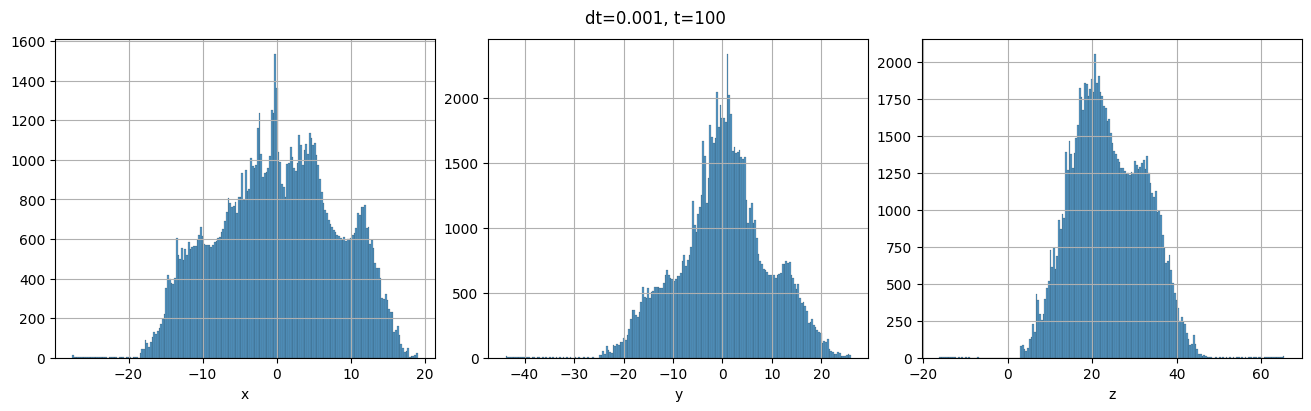

In [5]:
# Now reuse for any (dt, t) that are multiples/subsets
#dts = [0.01, 0.005, 0.001]
dts = [0.001]
ts  = [100]

for dt in dts:
    for t in ts:
        t_sub, x_sub, y_sub, z_sub = subset_trajectory(base, dt=dt, t=t)
        report_and_plot(dt, t, t_sub, x_sub, y_sub, z_sub)

In [6]:
def generation(dt, t):
  steps = int(t/dt + 1)

  xs = np.empty(steps + 1)
  ys = np.empty(steps + 1)
  zs = np.empty(steps + 1)
  ts = np.empty(steps + 1)


  xs[0], ys[0], zs[0]  = np.random.uniform(-20,20,3)
  ts[0] = 0

  for i in range(steps):
      x_dot, y_dot, z_dot = lorenz(xs[i], ys[i], zs[i])
      xs[i + 1] = xs[i] + (x_dot * dt)
      ys[i + 1] = ys[i] + (y_dot * dt)
      zs[i + 1] = zs[i] + (z_dot * dt)
      ts[i + 1] = ts[i] + dt

  df = pd.DataFrame({
        "t": ts,
        "x": xs,
        "y": ys,
        "z": zs,
    })

  return df

In [7]:
def overlay_distributions_(df: pd.DataFrame, steps: list[int], vars=["x", "y", "z"]):
    """
    Takes a trajectory DataFrame with columns [t, x, y, z]
    Returns a combined DF with both original and downsampled labeled, then plots overlaid lines.
    """
    # add Original label
    combined = df.copy()
    combined["Distribution"] = "Original"

    for step in steps:
        if step < 1:
            raise ValueError("Step must be >= 1")
        # downsampled copy
        stride = df.iloc[::step].copy()
        stride["Distribution"] = f"stride={step}"

        # combine
        combined = pd.concat([combined, stride], ignore_index=True)

    # reshape for facet plotting
    '''
    melted = combined.melt(
        id_vars=["t", "Distribution"],
        value_vars=vars,
        var_name="Variable",
        value_name="Value"
    )
    '''
    g = sns.lineplot(data=combined, x="t", y="x", hue="Distribution")
    plt.show()

    return combined



In [8]:
def overlay_distributions(df: pd.DataFrame, step: int, vars=["x", "y", "z"]):
    """
    Overlay original vs downsampled (stride) trajectories for Lorenz-63.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame with columns ["t", "x", "y", "z"]
    step : int
        Downsampling stride (e.g. 50)
    vars : list of str
        Which variables to plot (default ["x","y","z"])
    """

    # add Original label
    original = df.copy()
    original["Distribution"] = "Original"

    # downsampled copy
    stride_df = df.iloc[::step].copy()
    stride_df["Distribution"] = f"stride={step}"

    # combine
    combined = pd.concat([original, stride_df], ignore_index=True)
    combined = combined.melt(id_vars=["t", "Distribution"], value_vars=vars,
                             var_name="Variable", value_name="Value")

    # Plot
    plt.figure(figsize=(12, 10))
    g = sns.FacetGrid(combined, col="Variable", hue="Distribution",
                      sharex=True, sharey=False, height=3.8, aspect=1.6)
    g.map(sns.lineplot, "t", "Value", alpha=0.7)
    g.add_legend(title="Distribution")
    g.set_axis_labels("Time", "")
    g.set_titles(col_template="{col_name} trajectory")

    plt.subplots_adjust(top=0.85)
    g.fig.suptitle(f"Overlay of Original vs Downsampled (stride={step}) Lorenz63 trajectories",
                   fontsize=16)
    plt.show()

    return combined

<Figure size 1200x1000 with 0 Axes>

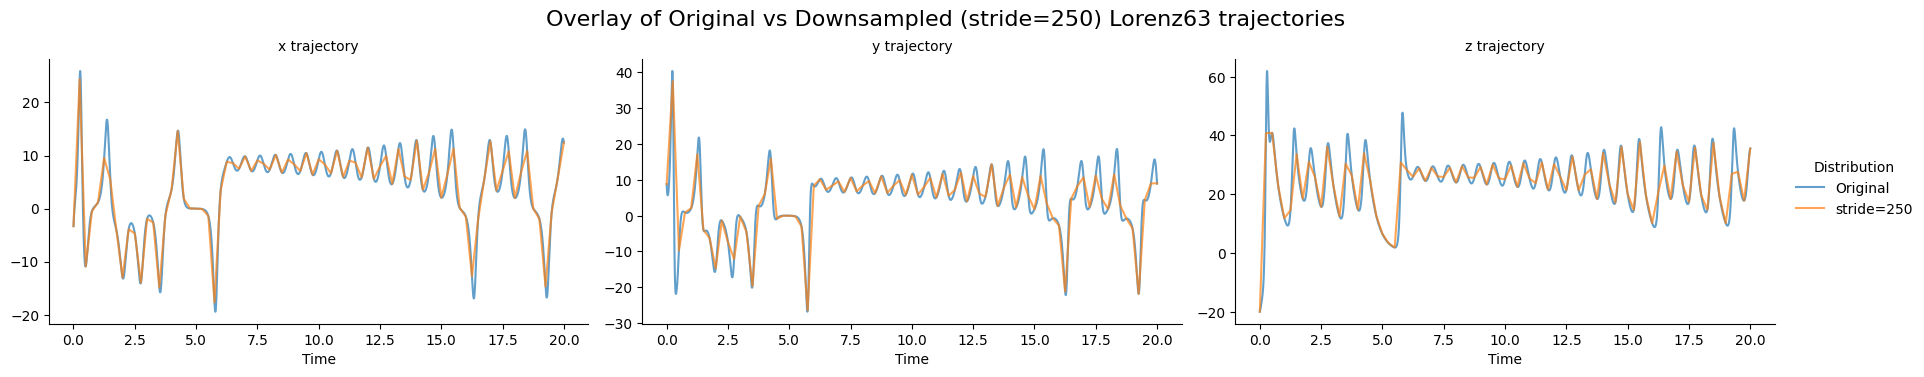

<Figure size 1200x1000 with 0 Axes>

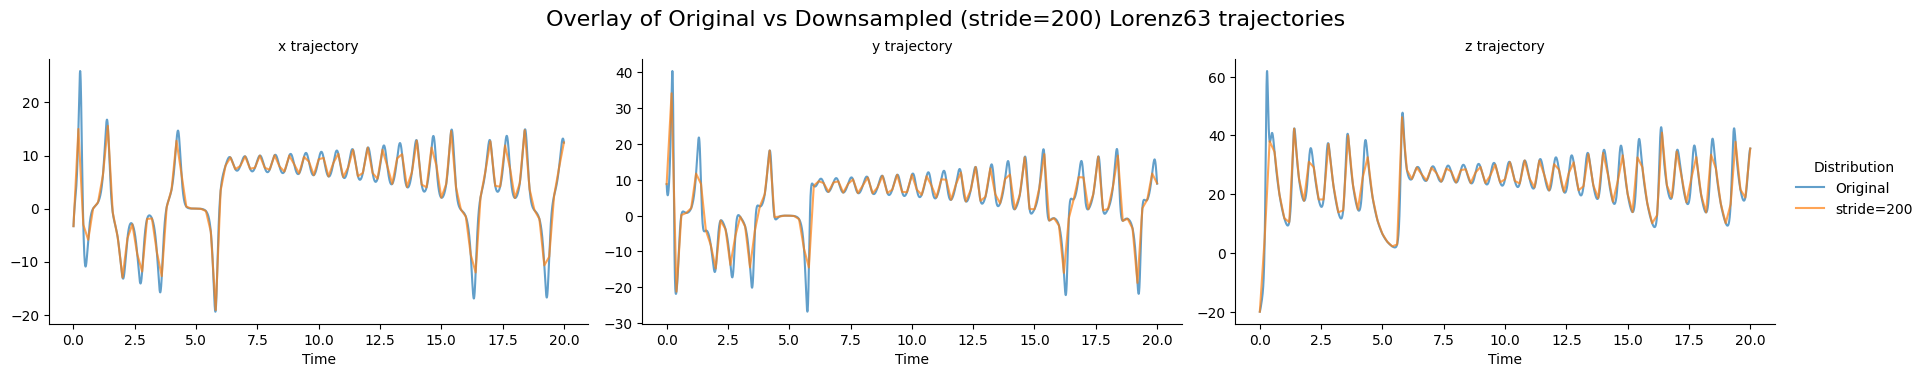

<Figure size 1200x1000 with 0 Axes>

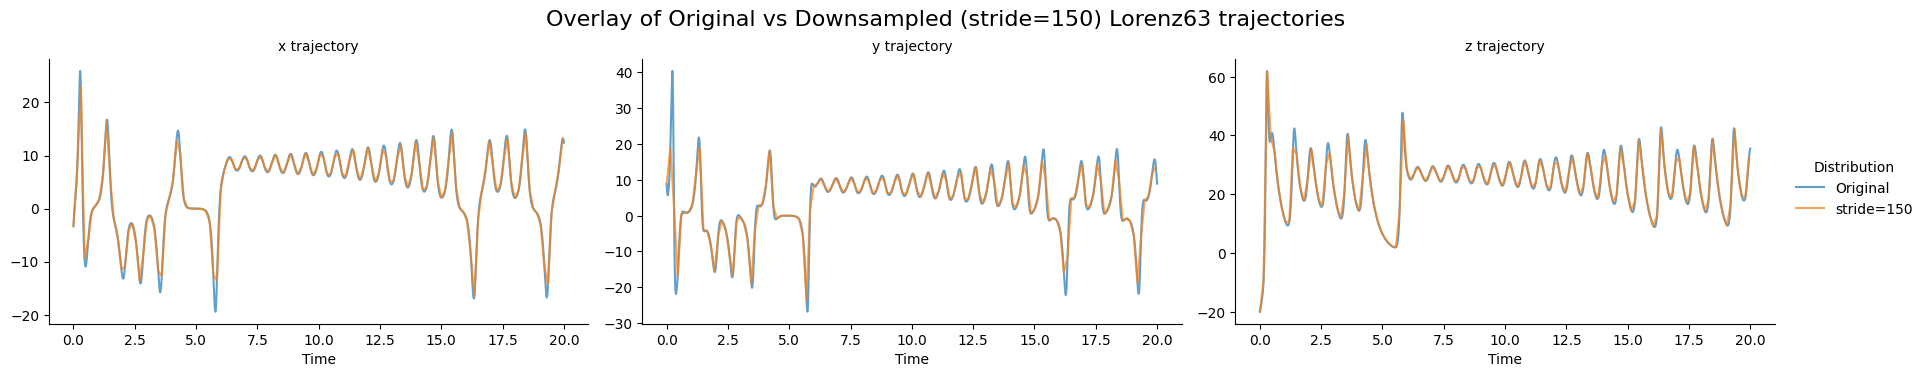

<Figure size 1200x1000 with 0 Axes>

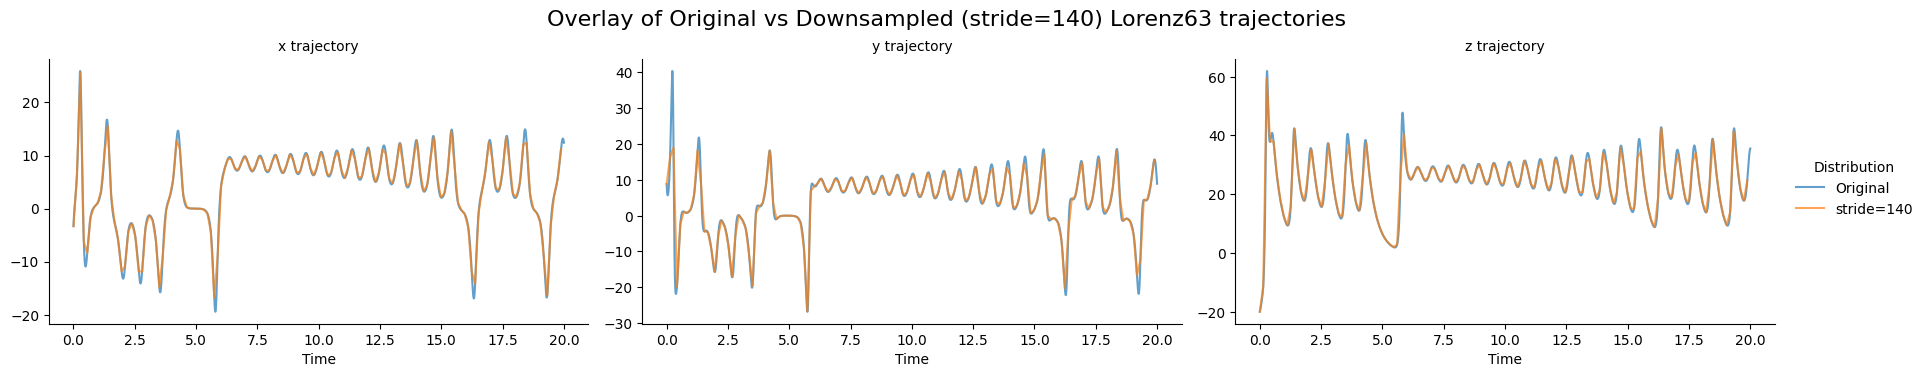

<Figure size 1200x1000 with 0 Axes>

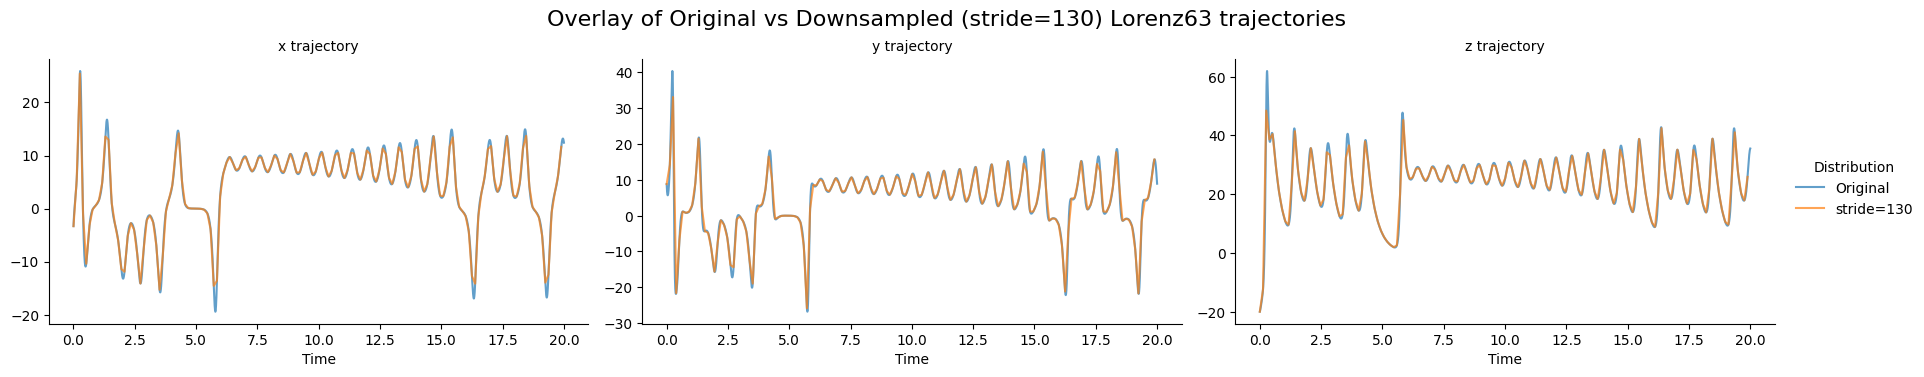

<Figure size 1200x1000 with 0 Axes>

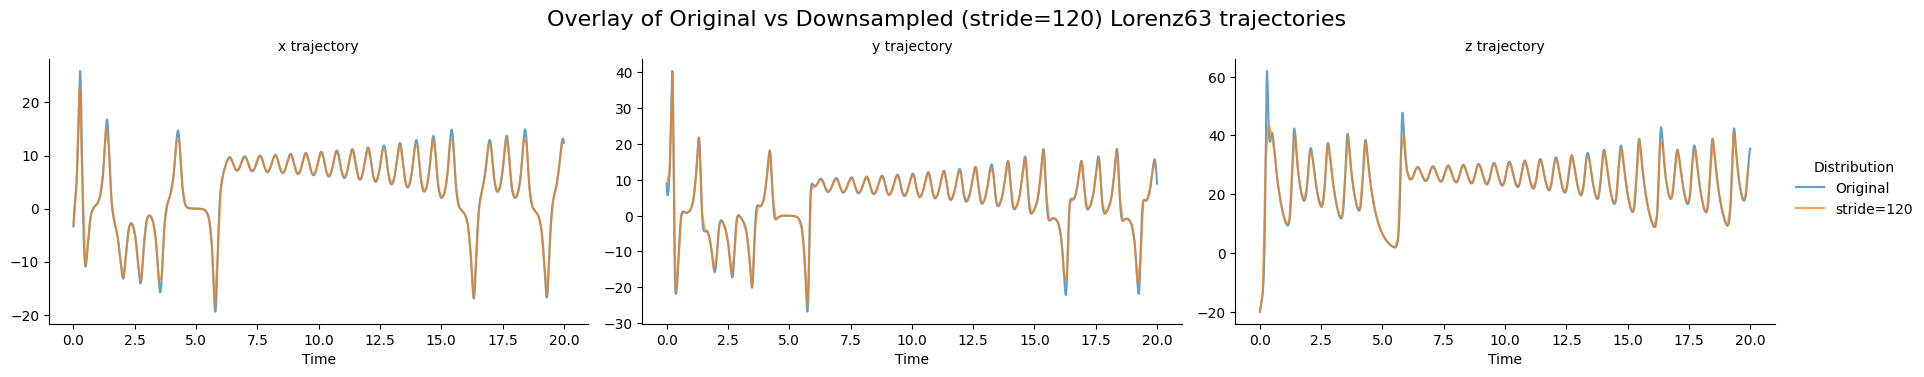

<Figure size 1200x1000 with 0 Axes>

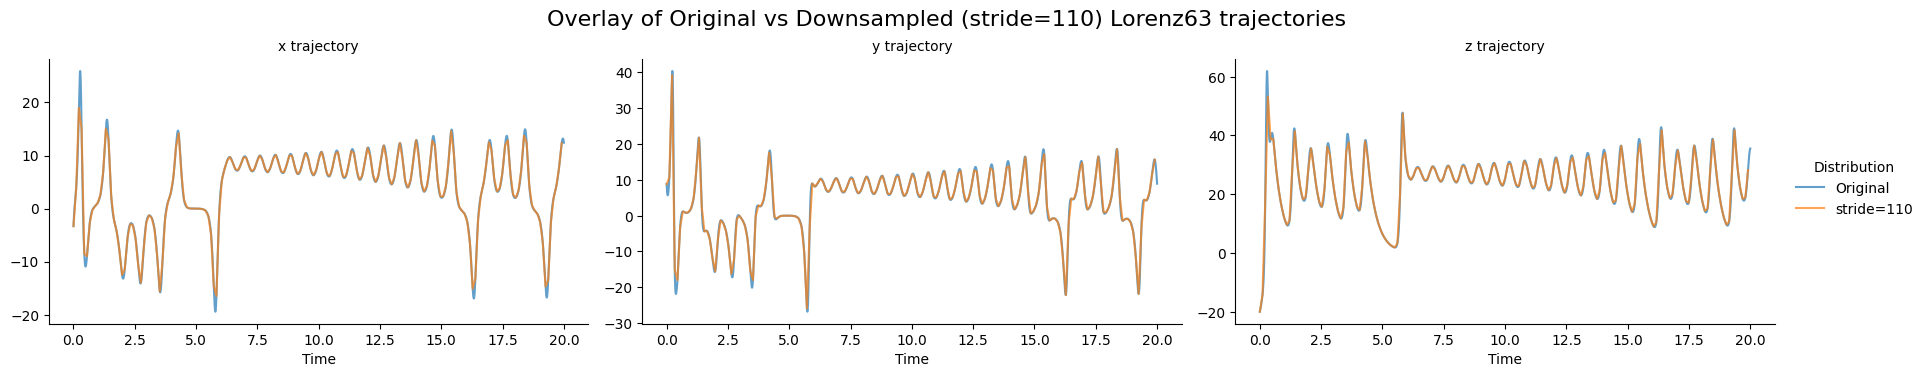

<Figure size 1200x1000 with 0 Axes>

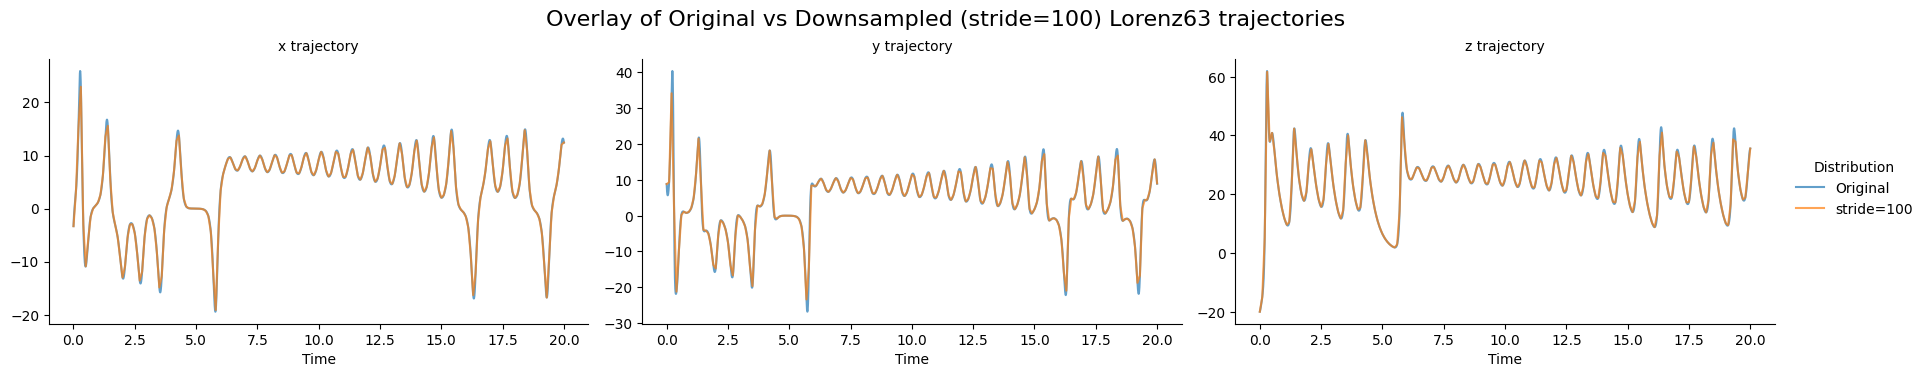

<Figure size 1200x1000 with 0 Axes>

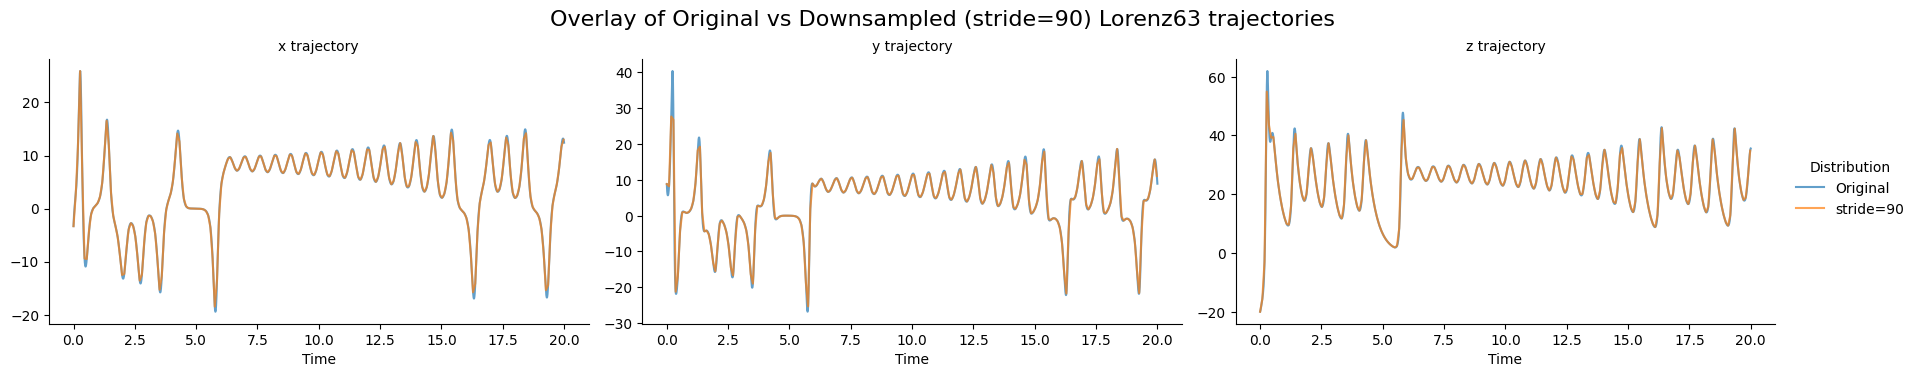

<Figure size 1200x1000 with 0 Axes>

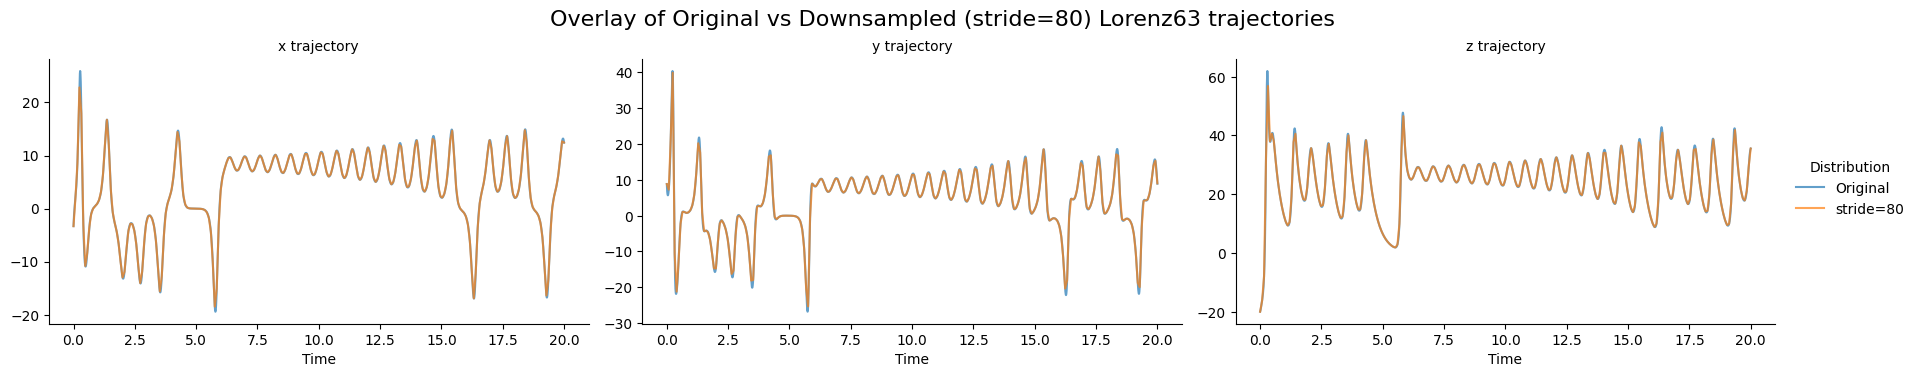

<Figure size 1200x1000 with 0 Axes>

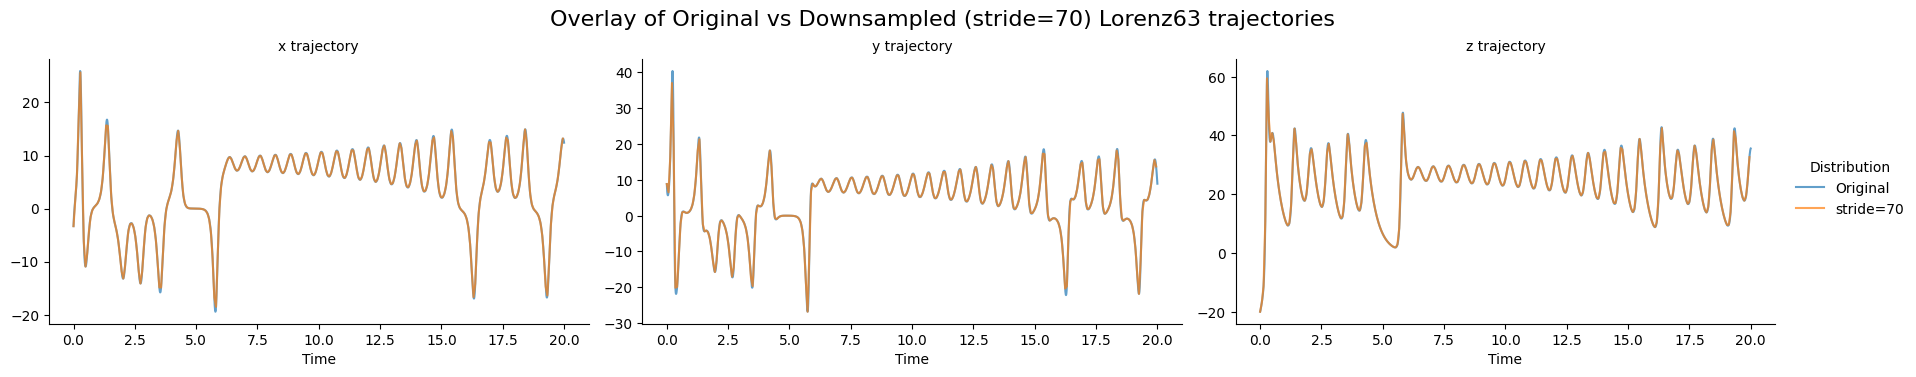

<Figure size 1200x1000 with 0 Axes>

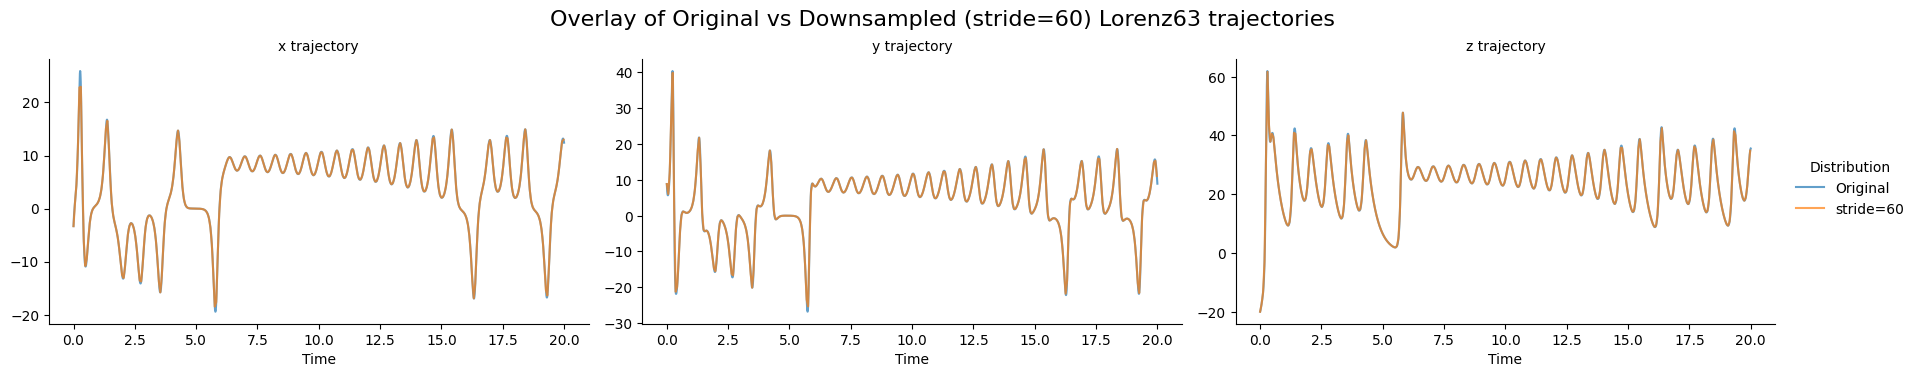

<Figure size 1200x1000 with 0 Axes>

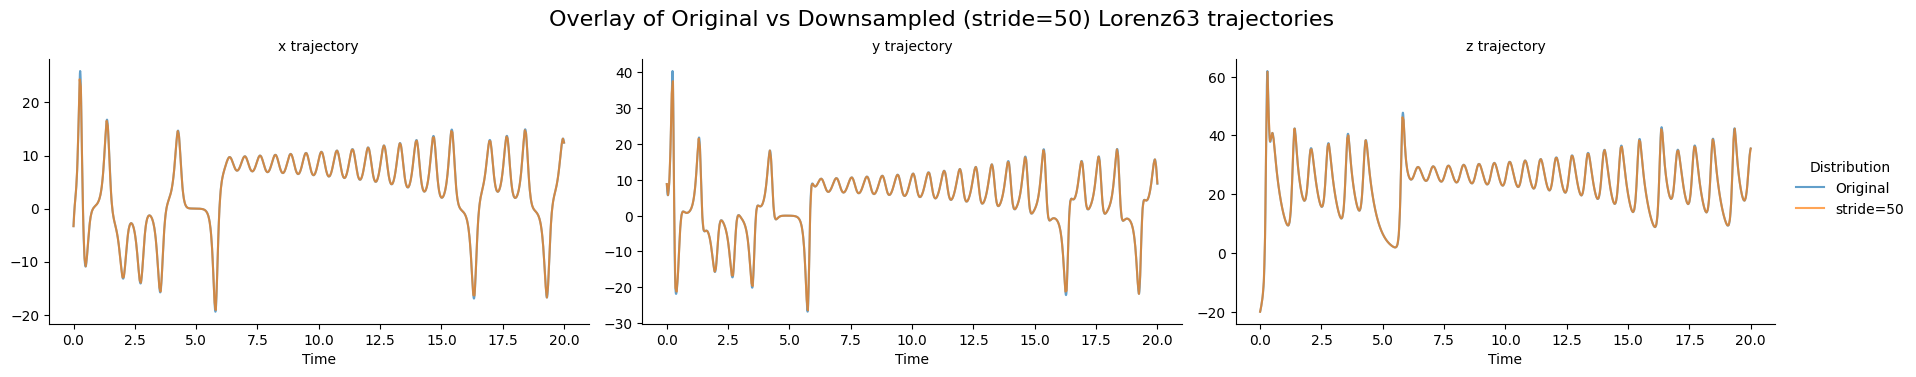

In [9]:
strides = (250, 200,150,140,130,120,110,100, 90, 80, 70, 60, 50)
df = generation(0.001, 20)   # your integrator -> returns DataFrame
for steps in [250, 200,150,140,130,120,110,100, 90, 80, 70, 60, 50]:
    overlay_df = overlay_distributions(df, step=steps)